In [40]:
import pandas as pd
import numpy as np

In [41]:
# 1. Reading the data
df_book = pd.read_csv('https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/books.csv')
print(df_book.columns.tolist())
df_book_tags = pd.read_csv('https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/book_tags.csv')
print(df_book_tags.columns.tolist())
df_ratings = pd.read_csv('https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/ratings.csv')
print(df_ratings.columns.tolist())
df_tags = pd.read_csv('https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/tags.csv')
print(df_tags.columns.tolist())

['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']
['goodreads_book_id', 'tag_id', 'count']
['user_id', 'book_id', 'rating']
['tag_id', 'tag_name']


In [42]:
# 2. Inspecting and cleaning the data
print(f'DataFrame Books: Empty = {df_book.isnull().sum().sum()}, Duplicate = {df_book.duplicated(subset=["title", "authors"]).sum()}')
print(f'DataFrame Book Tags: Empty = {df_book_tags.isnull().sum().sum()}, Duplicate = {df_book_tags.duplicated(subset=["goodreads_book_id", "tag_id"]).sum()}')
print(f'DataFrame Ratings: Empty = {df_ratings.isnull().sum().sum()}, Duplicate = {df_ratings.duplicated(subset=["user_id", "book_id"]).sum()}')
print(f'DataFrame Tags: Empty = {df_tags.isnull().sum().sum()}, Duplicate = {df_tags.duplicated(subset=["tag_name"]).sum()}')

# cleaning the df_book dataframe
print(df_book.isnull().sum()[df_book.isnull().sum() > 0]) # the only ones that are empty aren't critical for this project: 
                                                          # isbn, isbn13, original_publication_year, original_title, language_code
df_book.drop(columns=['isbn', 'isbn13'],inplace=True)
df_book['original_title'].fillna(df_book['title'])
df_book['language_code'].fillna('unknown')
df_book['original_publication_year'].fillna(0.0)

# cleaning the df_book_tags dataframe
df_book_tags = df_book_tags.drop_duplicates(subset=['goodreads_book_id', 'tag_id'])

# removing tags that aren't relevant for recommendation in df_tags
exact_noise = {
    "to-read", "currently-reading", "favorites", "favourites", "owned", "books-i-own", "library", "kindle", "ebook", "ebooks", "default",
    "audiobook", "audiobooks", "re-read", "reread", "dnf", "did-not-finish","borrowed", "calibre", "general", "shelfari-favorites", "reviewed"
}
noise_patterns = (
    r'to-read|to-be-read|tbr|owned|wish-list|wishlist|library|'
    r'read-in-|reads-|reading|favorite|favourite|book-club|series|'
    r'^[^a-z]*$'  # removes tags that are just numbers/years
)

df_tags['tag_name'] = df_tags['tag_name'].str.lower().str.strip().str.strip('-')
# due to this cleaning of the tag_name, there'll be duplicated values in df_tags but that'll be dealt with after

df_tags = df_tags[~df_tags['tag_name'].isin(exact_noise) & ~df_tags['tag_name'].str.contains(noise_patterns,regex=True)]

DataFrame Books: Empty = 2975, Duplicate = 0
DataFrame Book Tags: Empty = 0, Duplicate = 8
DataFrame Ratings: Empty = 0, Duplicate = 0
DataFrame Tags: Empty = 0, Duplicate = 0
isbn                          700
isbn13                        585
original_publication_year      21
original_title                585
language_code                1084
dtype: int64


In [43]:
# 3. Mapping df_book_tags and df_tags into df_books to consolidate in one dataframe
df_books_with_tags = pd.merge(df_book_tags, df_tags, on='tag_id', how='left') 
df_books_with_tags.drop(columns=['tag_id'], inplace=True)

# dealing with the duplicates that are inherited from df_tags due to the cleaning of tag_name
df_books_with_tags = df_books_with_tags.groupby(['goodreads_book_id', 'tag_name'],as_index=False)['count'].sum()

#collecting the top 10 most popular tags for each book
df_top10_tags = df_books_with_tags[df_books_with_tags.groupby('goodreads_book_id')['count'].rank(method='first', ascending=False) <= 10]

# merging the top 10 tags attributed to a book in a single row
df_row_book_tag = df_top10_tags.groupby('goodreads_book_id', as_index=False).agg({'tag_name': ', '.join})

df_books_info = pd.merge(df_book, df_row_book_tag, on='goodreads_book_id', how='left')
df_books_info.drop(columns=['goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'original_title', 'work_text_reviews_count', 'work_ratings_count'], inplace=True)
df_books_info.head()

,book_id,authors,original_publication_year,title,language_code,average_rating,ratings_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url,tag_name
0,1,Suzanne Collins,2008.0,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...,"adventure, dystopia, dystopian, fantasy, ficti..."
1,2,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...,"adventure, children, childrens, classics, fant..."
2,3,Stephenie Meyer,2005.0,"Twilight (Twilight, #1)",en-US,3.57,3866839,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...,"fantasy, fiction, paranormal, paranormal-roman..."
3,4,Harper Lee,1960.0,To Kill a Mockingbird,eng,4.25,3198671,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...,"classic, classics, clàssics, historical, histo..."
4,5,F. Scott Fitzgerald,1925.0,The Great Gatsby,eng,3.89,2683664,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...,"american-literature, classic, classics, fictio..."


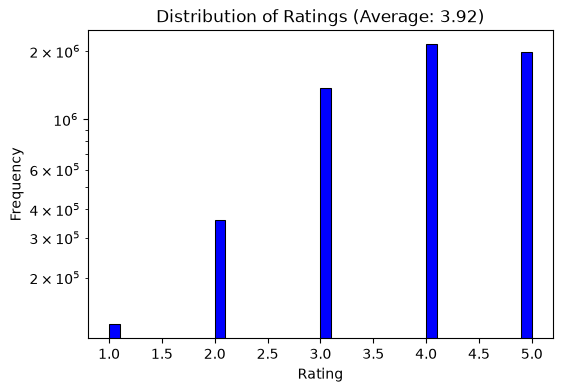

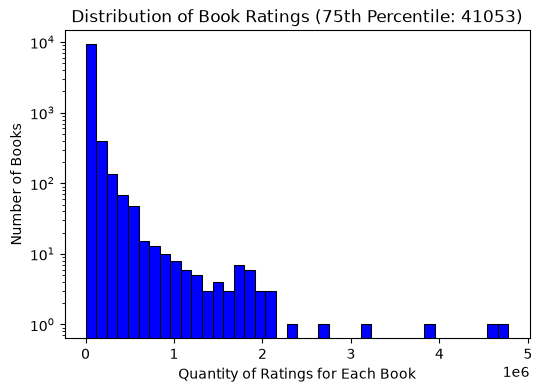

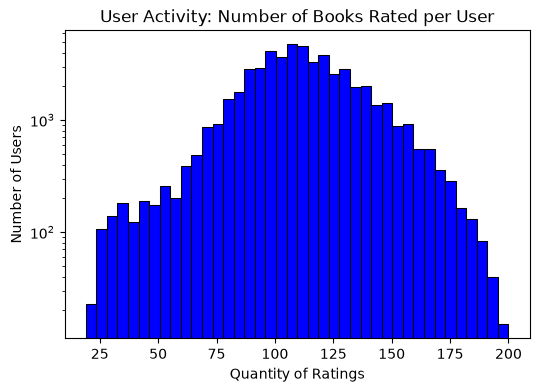

In [44]:
# 4. Exploratory Data Analysis (EDA)
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

plt.figure(figsize=(6, 4))

sns.histplot(df_ratings['rating'], bins=40, color='blue', alpha=1) # to check if there's a user tendency to give 4, 5 stars 
plt.yscale('log')
plt.ylabel('Frequency')
plt.xlabel('Rating')
plt.title(f'Distribution of Ratings (Average: {df_ratings['rating'].mean():.2f})')

plt.show()

plt.figure(figsize=(6, 4))

sns.histplot(df_books_info['ratings_count'], bins=40, color='blue', alpha=1) # to check if there's a long tail
                                                                             # meaning that there's only a couple of blockbuster books and most
                                                                             # has less than 100k ratings
plt.yscale('log')
plt.ylabel('Number of Books')
plt.xlabel('Quantity of Ratings for Each Book')
plt.title(f'Distribution of Book Ratings (75th Percentile: {int(np.percentile(df_books_info['ratings_count'], 75))})')

plt.show()

plt.figure(figsize=(6, 4))

sns.histplot(df_ratings['user_id'].value_counts(), bins=40, color='blue', alpha=1) # checking how active users are (most rate around 100-130 books)
plt.yscale('log')
plt.ylabel('Number of Users')
plt.xlabel('Quantity of Ratings')
plt.title('User Activity: Number of Books Rated per User')

plt.show()

In [45]:
# 5. Model 1 (Based on Book Average Rating and Popularity) - No Training
# it's necessary to calculate a weighted rating for each book due to the popularity of each title (books with less
# ratings may have an advantage when comparing average ratings)
v = df_books_info['ratings_count']
m = 40000 # based on the 75th percentile of the quantity of ratings for one book 
R = df_books_info['average_rating']
C = df_ratings['rating'].mean()
df_books_info['weighted_average_rating'] = (v/(v+m))*R+(m/(v+m))*C # IMDb weighted rating formula

# method to recommend books based on the quantity (default is top 10) the user wants and/or the genre (default is no specification)
def recommend_books(tag=None, top=10):
    popular_books = df_books_info[v > m].copy()
    if not tag:
        return popular_books.nlargest(top, 'weighted_average_rating').set_index('title')['authors'].to_dict()
    else:
        return popular_books[popular_books['tag_name'].str.contains(tag, case=False)].nlargest(top, 'weighted_average_rating').set_index('title')['authors'].to_dict()

print(recommend_books('sci-fi', 1))


{'The Name of the Wind (The Kingkiller Chronicle, #1)': 'Patrick Rothfuss'}


In [46]:
# Model 2 (Recommendation Based on Content) - Unsupervised Training
print(df_books_info.columns.tolist()) # checking the columns to see which ones are relevant to the training

# creating a dataframe for this model filtering unnecessary columns
df_content_based = df_books_info.drop(columns=['original_publication_year', 'language_code', 'average_rating', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url'])
df_content_based['content'] = df_content_based['authors'] + ' ' + df_content_based['title'] + ' ' + df_content_based['tag_name'] # parameters that will be compared between books

from sklearn.feature_extraction.text import TfidfVectorizer # necessary to transform similarity between books into numbers
from sklearn.metrics.pairwise import linear_kernel

tfid = TfidfVectorizer(stop_words='english', min_df=3, ngram_range=(1,2)) # removes common words like "the", discards words that appear only in 3 books
                                                                         # or less (to cap the size of the dictionary), gives higher weights to rare 
                                                                         # words, and splits the genres into 1 or 2 words
book_content_score = tfid.fit_transform(df_content_based['content'])
similarity_matrix = linear_kernel(book_content_score, book_content_score) # compare each book to one another to score how similar they are based on 
                                                                          # the parameters established on df_books_info['content']
def recommend_books_content(title, top=10, weight=1):
    book_pos, = np.where(df_content_based['title'].str.split('(').str[0].str.lower().str.strip() == title.lower().strip()) # finding the position of the book
    if len(book_pos) == 0:
        return None
    # calculates the score of a book to be recommended based on similarity and the normalized average rating (each parameter is weighted)
    similarity_book_rating = similarity_matrix[book_pos[0],:] * weight + df_content_based['weighted_average_rating'].to_numpy() / 5 * (1 - weight) 
    similarity_book_rating[book_pos] = -1 # removing the possibility of recommending the same book
    index_recommended_books = np.argsort(-similarity_book_rating)[:top] # ranks the scores from highest to lowest and only displays the desired qty
    return df_content_based.iloc[index_recommended_books][["title", "authors", "weighted_average_rating"]].to_dict(orient="records")

title = 'The Hunger Games'
for weight in np.arange(1, -0.05, -0.1): # to compare the recommendations based on the different weights
    recommended_books = recommend_books_content(title, 10, round(weight, 1))
    print(f"\n--- Weight (Similarity): {round(weight, 1)}       Weight (Rating): {round(1 - weight, 1)} ---")
    if not recommended_books:
        print(f"Book {title} not found.")
    else:
        for book in recommended_books:
            print(f"Book: {book['title']} by {book['authors']}")

['book_id', 'authors', 'original_publication_year', 'title', 'language_code', 'average_rating', 'ratings_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url', 'tag_name', 'weighted_average_rating']

--- Weight (Similarity): 1.0       Weight (Rating): 0.0 ---
Book: Mockingjay (The Hunger Games, #3) by Suzanne Collins
Book: The Hunger Games Trilogy Boxset (The Hunger Games, #1-3) by Suzanne Collins
Book: Catching Fire (The Hunger Games, #2) by Suzanne Collins
Book: The Hunger Pains: A Parody by The Harvard Lampoon
Book: The Hunger Games Tribute Guide by Emily Seife
Book: The World of the Hunger Games (Hunger Games Trilogy) by Kate Egan
Book: The Hunger Games: Official Illustrated Movie Companion by Kate Egan
Book: The Girl Who Was on Fire: Your Favorite Authors on Suzanne Collins' Hunger Games Trilogy by Leah Wilson, Jennifer Lynn Barnes, Mary Borsellino, Sarah Rees Brennan, Terri  Clark, Bree Despain, Adrienne Kress, Sarah Darer Littman

In [47]:
# 5.a. Finding the best weight for the similarity and the weighted rating - Fine tuning
def evaluate_weights(weight):
    hits = {}
    users = df_ratings['user_id'].unique()[:500] # selecting the first 500 users
    df_books_liked = df_ratings[(df_ratings['rating'] >= 4) & (df_ratings['user_id'].isin(users))] # filtering by only the books that the users liked
    df_books_liked_titled = pd.merge(df_books_liked, df_books_info, on='book_id', how='left') # retrieving the titles
    for user in users:
        hit = 0 # calculates how many recommended books are in the liked books list for each one of 500 sample users
        # sending the first liked book of the specific user to recommend 10 books
        recommended_books = recommend_books_content(df_books_liked_titled.loc[df_books_liked_titled['user_id'] == user, 'title'].iloc[0].split('(')[0].lower().strip(), 10, round(weight, 1))
        if not recommended_books: 
            continue
        for book in recommended_books:
            # if a recommended book is on the user's liked books, it counts as a hit 
            if book['title'] in df_books_liked_titled.loc[df_books_liked_titled['user_id'] == user, 'title'].tolist():
                hit += 1
            else:
                continue
        hits[str(user)] = hit
    return hits

for weight in np.arange(1, -0.05, -0.1):
    hits = evaluate_weights(weight)
    users_with_hits = sum(1 for h in hits.values() if h != 0) # calculates how many users had hits
    print(f"Weight (Similarity): {round(weight, 1)} ---> Total Hits = {sum(hits.values())}   Hits Rate = {users_with_hits / len(hits)}")

Weight (Similarity): 1.0 ---> Total Hits = 606   Hits Rate = 0.53
Weight (Similarity): 0.9 ---> Total Hits = 606   Hits Rate = 0.528
Weight (Similarity): 0.8 ---> Total Hits = 609   Hits Rate = 0.53
Weight (Similarity): 0.7 ---> Total Hits = 607   Hits Rate = 0.528
Weight (Similarity): 0.6 ---> Total Hits = 611   Hits Rate = 0.528
Weight (Similarity): 0.5 ---> Total Hits = 636   Hits Rate = 0.548
Weight (Similarity): 0.4 ---> Total Hits = 645   Hits Rate = 0.56
Weight (Similarity): 0.3 ---> Total Hits = 733   Hits Rate = 0.65
Weight (Similarity): 0.2 ---> Total Hits = 981   Hits Rate = 0.72
Weight (Similarity): 0.1 ---> Total Hits = 915   Hits Rate = 0.636
Weight (Similarity): 0.0 ---> Total Hits = 788   Hits Rate = 0.588


In [48]:
# 6. Model 3 - Supervised Training (Linear Regression)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error

df_books_linear = df_books_info[['book_id', 'weighted_average_rating', 'tag_name', 'authors']].copy()
df_ratings_sampled = df_ratings.sample(100000, random_state=1) # df_ratings has more than 6 million rows, to avoid crashing, sampling
del df_ratings_sampled['user_id']
df_linear_regression = pd.merge(df_ratings_sampled, df_books_linear, on='book_id', how='left')
del df_linear_regression['book_id'] # book_id was only needed to do the merge
df_linear_regression['tag_name'] = df_linear_regression['tag_name'].str.split(',').str[0].str.strip() # only uses the first tag of the book

df_full_train, df_test = train_test_split(df_linear_regression, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train.rating.values # y is what was the rating of a book from a user (1,2,3,4,5 stars)
y_val = df_val.rating.values

del df_train['rating']
del df_val['rating']

dv = DictVectorizer(sparse=True)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)
for alpha in [0.1, 1.0, 10.0, 100.0, 200.0, 500.0]: # finding the best alpha
    model = Ridge(alpha=alpha, random_state=1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    print(f"----------Alpha = {alpha}----------")
    print(f"RMSE = {rmse:.4f}")

----------Alpha = 0.1----------
RMSE = 0.9904
----------Alpha = 1.0----------
RMSE = 0.9772
----------Alpha = 10.0----------
RMSE = 0.9637
----------Alpha = 100.0----------
RMSE = 0.9605
----------Alpha = 200.0----------
RMSE = 0.9610
----------Alpha = 500.0----------
RMSE = 0.9628


In [49]:
# 7. Model 4 - Supervised Training (Random Forest)
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import export_text
# finding what is the best feature to make decisions and what is the value that is going to make the cut and what are the assigned values for the if/else
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- weighted_average_rating <= 3.93
|   |--- value: [3.64]
|--- weighted_average_rating >  3.93
|   |--- value: [4.07]



In [50]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

for depth in range(1, 21): # how many if/else questions provide the best RMSE
    print(f"-------Depth = {depth}-------")
    # how many trees result in the best RMSE for the specific depth, the smallest end point must have at least 10 ratings
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=depth, min_samples_leaf=10, n_jobs=-1, random_state=1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        print(f'Estimators = {n}   RMSE = {rmse:.4f}')

-------Depth = 1-------
Estimators = 10   RMSE = 0.9709
Estimators = 50   RMSE = 0.9706
Estimators = 100   RMSE = 0.9705
Estimators = 150   RMSE = 0.9705
-------Depth = 2-------
Estimators = 10   RMSE = 0.9639
Estimators = 50   RMSE = 0.9634
Estimators = 100   RMSE = 0.9634
Estimators = 150   RMSE = 0.9634
-------Depth = 3-------
Estimators = 10   RMSE = 0.9623
Estimators = 50   RMSE = 0.9620
Estimators = 100   RMSE = 0.9620
Estimators = 150   RMSE = 0.9620
-------Depth = 4-------
Estimators = 10   RMSE = 0.9616
Estimators = 50   RMSE = 0.9613
Estimators = 100   RMSE = 0.9613
Estimators = 150   RMSE = 0.9612
-------Depth = 5-------
Estimators = 10   RMSE = 0.9614
Estimators = 50   RMSE = 0.9609
Estimators = 100   RMSE = 0.9609
Estimators = 150   RMSE = 0.9609
-------Depth = 6-------
Estimators = 10   RMSE = 0.9613
Estimators = 50   RMSE = 0.9608
Estimators = 100   RMSE = 0.9607
Estimators = 150   RMSE = 0.9607
-------Depth = 7-------
Estimators = 10   RMSE = 0.9613
Estimators = 50   RM

In [51]:
# 8. Baseline Model based on the mean of y_train
y_pred_baseline = np.full(len(y_val), y_train.mean())
rmse = root_mean_squared_error(y_val, y_pred_baseline)
print(f"Training Mean Rating = {y_train.mean():.2f} RMSE = {rmse:.4f}")

Training Mean Rating = 3.92 RMSE = 0.9944


In [52]:
# 9. Comparing the 4 models, choosing the best, and using it for the test:
# The unsupervised model (content based model) has a best hit rate (weight = 0.2) of 0.72
# The ridge model has at alpha = 100.0 the best RMSE = 0.9605
# The random forest model has at (depth = 7, estimators = 100) the best RMSE = 0.9606
# The baseline model's RMSE = 0.9944
# Therefore, the best model is the ridge model with alpha = 100.0

y_full_train = df_full_train.rating.values
y_test = df_test.rating.values

df_full_train_clean = df_full_train.drop(columns='rating')
df_test_clean = df_test.drop(columns='rating')

dv = DictVectorizer(sparse=True)
full_train_dict = df_full_train_clean.to_dict(orient='records')
X_full_train = dv.fit_transform(full_train_dict)
test_dict = df_test_clean.to_dict(orient='records')
X_test = dv.transform(test_dict)
model = Ridge(alpha=100.0, random_state=1)
model.fit(X_full_train, y_full_train)
y_pred = model.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred)
print(f"Ridge Model (alpha = 100.0)--->RMSE = {rmse:.4f}")

Ridge Model (alpha = 100.0)--->RMSE = 0.9660
